# Train and evaluate pretrained Swin Tiny classifier

This notebook trains a `timm` pretrained `swin_tiny_patch4_window7_224` model adapted for five-channel beach-cell matrices. It uses split metadata from `Data/Preprocessed`, loads five channels per target cell with optional neighboring-cell context from `Data/Raw/beach_all`, applies training-only spatial augmentation, and evaluates the test set with per-class precision, recall, and F1 score.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").exists()
    or (PROJECT_ROOT / "Data").exists()
    or (PROJECT_ROOT / "pmaciag-volume-beach").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if (PROJECT_ROOT / "pmaciag-volume-beach").exists():
    PROJECT_ROOT = PROJECT_ROOT / "pmaciag-volume-beach"
if not ((PROJECT_ROOT / "Source").exists() or (PROJECT_ROOT / "Data").exists()):
    raise RuntimeError("Could not locate pmaciag-volume-beach project directory.")

source_path = PROJECT_ROOT / "Source"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    BeachCellDataset,
    FEATURE_SUFFIXES,
    class_weights,
    compute_channel_stats,
    find_missing_files,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
    summarize_nonfinite_values,
)
from Source.grid_search import run_grid_search
from Source.models import build_swin_tiny
from Source.training import classification_metrics, fit_model, get_device, predict

In [2]:
CELL_DATA_ROOT = PROJECT_ROOT / "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
PREPROCESSED_DIR = PROJECT_ROOT / "Data" / "Preprocessed"
OUTPUT_DIR = PROJECT_ROOT / "Results" / "swin_tiny"

TRAIN_SPLIT = PREPROCESSED_DIR / "train_split.csv"
VALIDATION_SPLIT = PREPROCESSED_DIR / "validation_split.csv"
TEST_SPLIT = PREPROCESSED_DIR / "test_split.csv"

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 8
EPOCHS = 50
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MIN_DELTA = 1e-4
USE_SPATIAL_AUGMENTATION = True
SWIN_MODEL_NAME = "swin_tiny_patch4_window7_224"
USE_PRETRAINED_IMAGENET_WEIGHTS = True
BASE_PARAMETER_GRID = [
    {"learning_rate": 1e-4, "weight_decay": 1e-4, "dropout": 0.0, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 3e-5, "weight_decay": 1e-4, "dropout": 0.0, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 1e-4, "weight_decay": 1e-3, "dropout": 0.1, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 3e-5, "weight_decay": 1e-3, "dropout": 0.1, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
]
CONTEXT_RADII = [0, 1, 2]
PARAMETER_GRID = [
    {**config, "context_radius": context_radius}
    for context_radius in CONTEXT_RADII
    for config in BASE_PARAMETER_GRID
]
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

print(f"Project root:    {PROJECT_ROOT}", flush=True)
print(f"Cell data root:  {CELL_DATA_ROOT}", flush=True)
print(f"Class mapping:   {CLASS_MAPPING_PATH}", flush=True)
print(f"Output dir:      {OUTPUT_DIR}", flush=True)
print(f"Feature order:   {FEATURE_SUFFIXES}", flush=True)

Project root:    /workspace/pmaciag-volume-beach


Cell data root:  /workspace/pmaciag-volume-beach/Data/Raw/beach_all


Class mapping:   /workspace/pmaciag-volume-beach/Data/Raw/Classes.xlsx


Output dir:      /workspace/pmaciag-volume-beach/Results/swin_tiny


Feature order:   ('r', 'g', 'b', 's', 'd')


In [3]:
print("Loading dataset splits and class mapping...", flush=True)
train_df = read_split_csv(TRAIN_SPLIT)
validation_df = read_split_csv(VALIDATION_SPLIT)
test_df = read_split_csv(TEST_SPLIT)

class_to_idx = make_class_mapping(train_df, validation_df, test_df)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
idx_to_class_code = {idx: label for label, idx in class_to_idx.items()}
idx_to_class_name = {
    idx: f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for idx, code in idx_to_class_code.items()
}

class_table = pd.DataFrame(
    [
        {"encoded_class": code, "model_index": idx, "class_name": class_name_by_code.get(code, f"class_{code}")}
        for code, idx in class_to_idx.items()
    ]
).sort_values("model_index")

if all(name == f"class_{code}" for code, name in class_name_by_code.items()):
    print(
        "No class-name mapping was detected in Classes.xlsx; "
        "using fallback labels class_0, class_1, ..."
    )

print(f"Train rows:      {len(train_df):,}")
print(f"Validation rows: {len(validation_df):,}")
print(f"Test rows:       {len(test_df):,}")
display(class_table)

Loading dataset splits and class mapping...


Train rows:      5,685
Validation rows: 1,218
Test rows:       1,219


,encoded_class,model_index,class_name
0,0,0,Snow
1,1,1,Dry sediment
2,2,2,Wet sediment
3,3,3,Water
4,4,4,Bedrock
5,5,5,Boulder
6,6,6,Driftwood
7,7,7,Algae
8,8,8,Ice
9,9,9,Anthropogenic


In [4]:
print("Checking external cell data root and a small file sample...", flush=True)
all_splits_df = pd.concat([train_df, validation_df, test_df], ignore_index=True)

if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(
        f"External cell data directory not found: {CELL_DATA_ROOT}. "
        "Mount the external drive before running training."
    )

sanity_rows = all_splits_df.head(min(20, len(all_splits_df)))
missing_files = find_missing_files(sanity_rows, CELL_DATA_ROOT)

if not missing_files.empty:
    display(missing_files)
    raise FileNotFoundError(
        "Some target matrix files are missing in the external data root. "
        "Inspect the missing files above."
    )

print(
    f"External cell data root is available. "
    f"Checked {len(sanity_rows):,} target cells as a quick sanity check.",
    flush=True,
)
print(
    "Full target/context file availability is checked lazily while loading batches, "
    "which avoids a slow preflight scan of the external volume.",
    flush=True,
)

Checking external cell data root and a small file sample...


External cell data root is available. Checked 20 target cells as a quick sanity check.


Full target/context file availability is checked lazily while loading batches, which avoids a slow preflight scan of the external volume.


In [5]:
print("Checking sampled nonfinite values and computing training normalization statistics...", flush=True)
NONFINITE_SANITY_ROWS = train_df.head(min(20, len(train_df)))
nonfinite_values = summarize_nonfinite_values(NONFINITE_SANITY_ROWS, CELL_DATA_ROOT)
if nonfinite_values.empty:
    print(f"No NaN, -999, or infinite values found in {len(NONFINITE_SANITY_ROWS):,} sampled training target cells.", flush=True)
else:
    display(
        nonfinite_values
        .groupby(["split" if "split" in nonfinite_values.columns else "date", "feature"], dropna=False)
        .agg(files=("path", "count"), nan_values=("nan_count", "sum"), inf_values=("inf_count", "sum"))
    )
    display(nonfinite_values.head(20))

channel_stats_cache = {}
base_channel_stats = compute_channel_stats(
    train_df,
    CELL_DATA_ROOT,
    FEATURE_SUFFIXES,
    context_radius=0,
)


def get_channel_stats(context_radius):
    context_radius = int(context_radius)
    if context_radius not in channel_stats_cache:
        channel_stats_cache[context_radius] = base_channel_stats
    return channel_stats_cache[context_radius]

stats_rows = []
for context_radius in sorted({int(config["context_radius"]) for config in PARAMETER_GRID}):
    mean, std = get_channel_stats(context_radius)
    for feature, feature_mean, feature_std in zip(FEATURE_SUFFIXES, mean, std):
        stats_rows.append(
            {
                "context_radius": context_radius,
                "feature": feature,
                "mean": feature_mean,
                "std": feature_std,
                "estimated_from": "training_target_cells_only",
            }
        )

stats_df = pd.DataFrame(stats_rows)
print("Finished computing normalization statistics.", flush=True)
stats_df

Checking sampled nonfinite values and computing training normalization statistics...


No NaN, -999, or infinite values found in 20 sampled training target cells.


Finished computing normalization statistics.


,context_radius,feature,mean,std,estimated_from
0,0,r,120.245041,45.008991,training_target_cells_only
1,0,g,123.630508,46.351540,training_target_cells_only
2,0,b,127.412636,48.152916,training_target_cells_only
3,0,s,15.951724,13.280346,training_target_cells_only
4,0,d,0.709507,1.065230,training_target_cells_only
5,1,r,120.245041,45.008991,training_target_cells_only
6,1,g,123.630508,46.351540,training_target_cells_only
7,1,b,127.412636,48.152916,training_target_cells_only
8,1,s,15.951724,13.280346,training_target_cells_only
9,1,d,0.709507,1.065230,training_target_cells_only


In [6]:
print("Building dataset/DataLoader factories and reading one sample batch...", flush=True)
def make_datasets(context_radius):
    channel_mean, channel_std = get_channel_stats(context_radius)
    train_dataset = BeachCellDataset(
        train_df,
        CELL_DATA_ROOT,
        class_to_idx,
        image_size=IMAGE_SIZE,
        mean=channel_mean,
        std=channel_std,
        augment=USE_SPATIAL_AUGMENTATION,
        context_radius=context_radius,
    )
    validation_dataset = BeachCellDataset(
        validation_df,
        CELL_DATA_ROOT,
        class_to_idx,
        image_size=IMAGE_SIZE,
        mean=channel_mean,
        std=channel_std,
        context_radius=context_radius,
    )
    test_dataset = BeachCellDataset(
        test_df,
        CELL_DATA_ROOT,
        class_to_idx,
        image_size=IMAGE_SIZE,
        mean=channel_mean,
        std=channel_std,
        context_radius=context_radius,
    )
    return train_dataset, validation_dataset, test_dataset, channel_mean, channel_std


def make_train_validation_loaders(config):
    context_radius = int(config["context_radius"])
    train_dataset, validation_dataset, _, _, _ = make_datasets(context_radius)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )
    return train_loader, validation_loader


sample_context_radius = int(PARAMETER_GRID[0]["context_radius"])
sample_train_dataset, _, _, sample_mean, sample_std = make_datasets(sample_context_radius)
sample_loader = DataLoader(
    sample_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

x_batch, y_batch = next(iter(sample_loader))
print(f"Sample context radius: {sample_context_radius}", flush=True)
print(f"Input batch shape: {tuple(x_batch.shape)}", flush=True)
print(f"Label batch shape: {tuple(y_batch.shape)}", flush=True)

Building dataset/DataLoader factories and reading one sample batch...


Sample context radius: 0


Input batch shape: (32, 5, 224, 224)


Label batch shape: (32,)


In [7]:
print("Selecting compute device and preparing model factory...", flush=True)
device = get_device()
weights = class_weights(train_df, class_to_idx)

def model_factory(config):
    return build_swin_tiny(
        num_classes=len(class_to_idx),
        in_channels=len(FEATURE_SUFFIXES),
        pretrained=bool(config["pretrained"]),
        model_name=SWIN_MODEL_NAME,
        dropout=float(config["dropout"]),
    )

print(f"Device: {device}", flush=True)
print(f"Grid configurations: {len(PARAMETER_GRID)}", flush=True)

Selecting compute device and preparing model factory...


Device: cuda


Grid configurations: 12


In [8]:
print("Starting grid search training...", flush=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = OUTPUT_DIR / "swin_tiny_best.pt"

grid_result = run_grid_search(
    model_factory=model_factory,
    parameter_grid=PARAMETER_GRID,
    train_loader=None,
    validation_loader=None,
    loader_factory=make_train_validation_loaders,
    class_weights=weights,
    idx_to_class=idx_to_class_name,
    device=device,
    epochs=EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    random_seed=RANDOM_SEED,
)

print("Grid search training finished. Saving best model and result files...", flush=True)
model = grid_result.model
history = grid_result.history
best_config = grid_result.config
validation_report = grid_result.validation_report
best_context_radius = int(best_config["context_radius"])
_, _, test_dataset, channel_mean, channel_std = make_datasets(best_context_radius)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

torch.save(
    {key: value.detach().cpu() for key, value in model.state_dict().items()},
    checkpoint_path,
)

best_config_path = OUTPUT_DIR / "best_config.json"
with best_config_path.open("w", encoding="utf-8") as file:
    json.dump(best_config, file, indent=2)

normalization_stats_path = OUTPUT_DIR / "normalization_stats.csv"
normalization_stats = pd.DataFrame(
    {
        "feature": FEATURE_SUFFIXES,
        "mean": channel_mean,
        "std": channel_std,
        "context_radius": best_context_radius,
    }
)
normalization_stats.to_csv(normalization_stats_path, index=False)

inference_metadata_path = OUTPUT_DIR / "inference_metadata.json"
inference_metadata = {
    "model_type": "swin_tiny",
    "checkpoint_filename": checkpoint_path.name,
    "model_name": SWIN_MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "context_radius": best_context_radius,
    "context_window_size": 2 * best_context_radius + 1,
    "feature_suffixes": list(FEATURE_SUFFIXES),
    "in_channels": len(FEATURE_SUFFIXES),
    "num_classes": len(class_to_idx),
    "class_to_idx": class_to_idx,
    "idx_to_class_code": idx_to_class_code,
    "class_name_by_code": class_name_by_code,
    "best_config": best_config,
    "channel_mean": [float(value) for value in channel_mean],
    "channel_std": [float(value) for value in channel_std],
}
with inference_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(inference_metadata, file, indent=2)

best_validation_report_path = OUTPUT_DIR / "best_validation_classification_report.csv"
validation_report.to_csv(best_validation_report_path)

grid_search_summary_path = OUTPUT_DIR / "grid_search_summary.csv"
grid_result.summary.to_csv(grid_search_summary_path, index=False)

best_grid_result_path = OUTPUT_DIR / "best_grid_search_result.csv"
grid_result.summary.head(1).to_csv(best_grid_result_path, index=False)

grid_search_metric_trace_path = OUTPUT_DIR / "grid_search_validation_metric_trace.csv"
grid_result.metric_trace.to_csv(grid_search_metric_trace_path, index=False)

history_path = OUTPUT_DIR / "training_history.csv"
history.to_csv(history_path, index=False)

print(f"Best context radius: {best_context_radius}", flush=True)
print("Saved training artifacts. Displaying best grid-search result.", flush=True)
display(grid_result.summary.head(1))
history

Starting grid search training...


Starting grid run 1 on cuda: config={'learning_rate': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.0, 'pretrained': True, 'context_radius': 0}


Finished grid run 1 on cuda: macro F1=0.8000, epochs=10, config={'learning_rate': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.0, 'pretrained': True, 'context_radius': 0}


Starting grid run 2 on cuda: config={'learning_rate': 3e-05, 'weight_decay': 0.0001, 'dropout': 0.0, 'pretrained': True, 'context_radius': 0}


Finished grid run 2 on cuda: macro F1=0.8534, epochs=21, config={'learning_rate': 3e-05, 'weight_decay': 0.0001, 'dropout': 0.0, 'pretrained': True, 'context_radius': 0}


...

Grid search training finished. Saving best model and result files...


Best context radius: 2


Saved training artifacts. Displaying best grid-search result.


,learning_rate,weight_decay,dropout,pretrained,context_radius,run_index,device,epochs_trained,best_validation_loss,best_validation_accuracy,validation_macro_f1
8,0.0001,0.0001,0.0,True,2,9,cuda,14,0.193421,0.92775,0.94558


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,is_best_epoch
0,1,0.878379,0.636588,0.540929,0.781609,False
1,2,0.385705,0.813193,0.330794,0.856322,False
2,3,0.315595,0.857872,0.283189,0.851396,False
3,4,0.215086,0.888303,0.377189,0.809524,False
4,5,0.200629,0.908531,0.264436,0.876026,False
5,6,0.170984,0.914160,0.253454,0.891626,False
6,7,0.194943,0.906420,0.296688,0.871100,False
7,8,0.136876,0.935268,0.208882,0.910509,False
8,9,0.104463,0.945119,0.193421,0.927750,True
9,10,0.083376,0.956904,0.302223,0.896552,False


Saving training history plot...


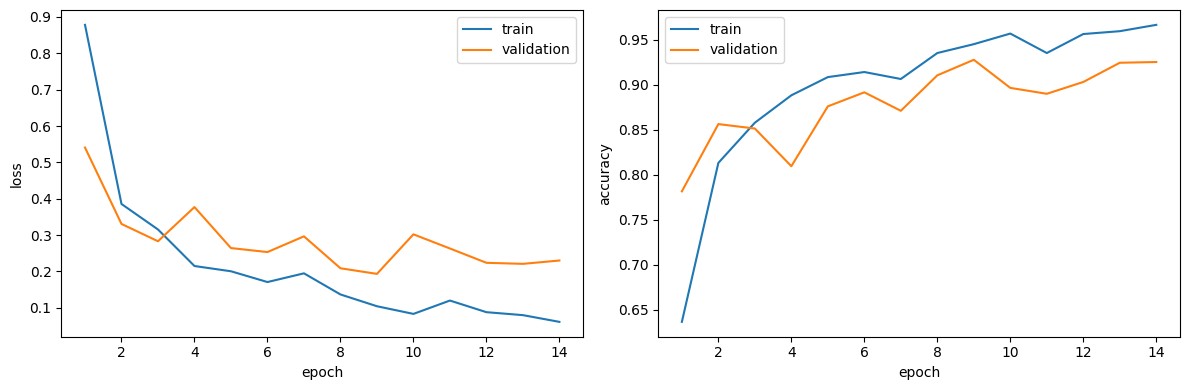

In [9]:
print("Saving training history plot...", flush=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="train")
axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], label="train")
axes[1].plot(history["epoch"], history["validation_accuracy"], label="validation")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_history.png", dpi=150)
plt.show()

In [10]:
print("Evaluating best model on the test split...", flush=True)
y_true, y_pred, y_probability = predict(model, test_loader, device)
print("Saved test classification outputs.", flush=True)
report_df, confusion_df = classification_metrics(y_true, y_pred, idx_to_class_name)

report_path = OUTPUT_DIR / "test_classification_report.csv"
confusion_path = OUTPUT_DIR / "test_confusion_matrix.csv"

report_df.to_csv(report_path)
confusion_df.to_csv(confusion_path)

report_df

Evaluating best model on the test split...


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Saved test classification outputs.


,precision,recall,f1-score,support
0: Snow,0.809524,1.000000,0.894737,17.000000
1: Dry sediment,0.952381,0.893855,0.922190,358.000000
2: Wet sediment,0.886364,0.898618,0.892449,217.000000
3: Water,0.977778,0.880000,0.926316,100.000000
4: Bedrock,0.936937,0.981132,0.958525,106.000000
5: Boulder,0.960000,0.989691,0.974619,97.000000
6: Driftwood,0.951807,0.987500,0.969325,80.000000
7: Algae,0.874126,0.968992,0.919118,129.000000
8: Ice,0.971963,0.954128,0.962963,109.000000
9: Anthropogenic,0.750000,1.000000,0.857143,6.000000


Saving confusion matrix plot...


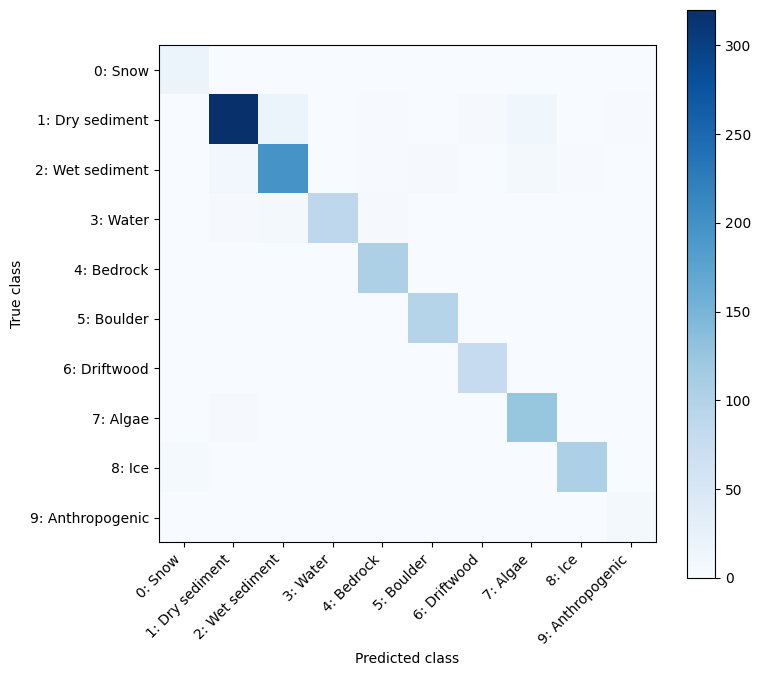

,0: Snow,1: Dry sediment,2: Wet sediment,3: Water,4: Bedrock,5: Boulder,6: Driftwood,7: Algae,8: Ice,9: Anthropogenic
0: Snow,17,0,0,0,0,0,0,0,0,0
1: Dry sediment,0,320,17,1,2,0,3,12,1,2
2: Wet sediment,0,8,195,1,2,3,0,6,2,0
3: Water,0,3,5,88,3,0,1,0,0,0
4: Bedrock,0,1,1,0,104,0,0,0,0,0
5: Boulder,0,0,1,0,0,96,0,0,0,0
6: Driftwood,0,1,0,0,0,0,79,0,0,0
7: Algae,0,3,1,0,0,0,0,125,0,0
8: Ice,4,0,0,0,0,1,0,0,104,0
9: Anthropogenic,0,0,0,0,0,0,0,0,0,6


In [11]:
print("Saving confusion matrix plot...", flush=True)
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion_df.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(confusion_df.columns)))
ax.set_yticks(range(len(confusion_df.index)))
ax.set_xticklabels(confusion_df.columns, rotation=45, ha="right")
ax.set_yticklabels(confusion_df.index)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

confusion_df

In [12]:
print("Saving test predictions...", flush=True)
prediction_df = test_df.reset_index(drop=True).copy()
prediction_df["true_class_code"] = [idx_to_class_code[int(idx)] for idx in y_true]
prediction_df["predicted_class_code"] = [idx_to_class_code[int(idx)] for idx in y_pred]
prediction_df["true_class_name"] = [class_name_by_code[prediction_df.loc[i, "true_class_code"]] for i in range(len(prediction_df))]
prediction_df["predicted_class_name"] = [class_name_by_code[prediction_df.loc[i, "predicted_class_code"]] for i in range(len(prediction_df))]

for idx, class_code in idx_to_class_code.items():
    prediction_df[f"probability_class_{class_code}"] = y_probability[:, idx]

prediction_path = OUTPUT_DIR / "test_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

print(f"Saved checkpoint: {checkpoint_path}")
print(f"Saved best config: {best_config_path}")
print(f"Saved normalization stats: {normalization_stats_path}")
print(f"Saved inference metadata: {inference_metadata_path}")
print(f"Saved best validation report: {best_validation_report_path}")
print(f"Saved grid summary: {grid_search_summary_path}")
print(f"Saved best grid result: {best_grid_result_path}")
print(f"Saved grid metric trace: {grid_search_metric_trace_path}")
print(f"Saved history:    {history_path}")
print(f"Saved report:     {report_path}")
print(f"Saved confusion:  {confusion_path}")
print(f"Saved predictions:{prediction_path}")

prediction_df.head()
print(f"Saved predictions to {prediction_path}", flush=True)

Saving test predictions...


Saved checkpoint: /workspace/pmaciag-volume-beach/Results/swin_tiny/swin_tiny_best.pt
Saved best config: /workspace/pmaciag-volume-beach/Results/swin_tiny/best_config.json
Saved normalization stats: /workspace/pmaciag-volume-beach/Results/swin_tiny/normalization_stats.csv
Saved inference metadata: /workspace/pmaciag-volume-beach/Results/swin_tiny/inference_metadata.json
Saved best validation report: /workspace/pmaciag-volume-beach/Results/swin_tiny/best_validation_classification_report.csv
Saved grid summary: /workspace/pmaciag-volume-beach/Results/swin_tiny/grid_search_summary.csv
Saved best grid result: /workspace/pmaciag-volume-beach/Results/swin_tiny/best_grid_search_result.csv
Saved grid metric trace: /workspace/pmaciag-volume-beach/Results/swin_tiny/grid_search_validation_metric_trace.csv
Saved history:    /workspace/pmaciag-volume-beach/Results/swin_tiny/training_history.csv
Saved report:     /workspace/pmaciag-volume-beach/Results/swin_tiny/test_classification_report.csv
Saved 